# Why don't customers come back?

Three angles:
1. **Cohort retention:** of the customers who first bought in a given month, how many ever bought again?
2. **Time to return:** when customers do come back, how long does it take?
3. **What the first order predicts:** does a late delivery, a bad review, the category, or the region of a
   customer's first order change the odds that they return within 180 days?

A second order on the same day as the first counts as the same shopping trip, not a return.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SQL = ROOT / "sql"
IMAGES = ROOT / "images"

load_dotenv(ROOT / ".env")
engine = create_engine(os.environ["DATABASE_URL"])


def run_sql(name):
    return pd.read_sql((SQL / f"{name}.sql").read_text(), engine)


with engine.begin() as conn:
    conn.execute(text((SQL / "first_orders.sql").read_text()))

pd.read_sql("""
SELECT
    COUNT(*) AS customers,
    SUM(CASE WHEN returned_at IS NOT NULL THEN 1 ELSE 0 END) AS ever_returned,
    ROUND(AVG(CASE WHEN returned_at IS NOT NULL THEN 1.0 ELSE 0 END) * 100, 2) AS ever_returned_pct
FROM first_orders
""", engine)

,customers,ever_returned,ever_returned_pct
0,94990,2065,2.17


### 1. Cohort retention

In [2]:
cohorts = run_sql("cohort_retention")
matrix = cohorts.pivot(index="cohort_month", columns="month_number", values="retention_pct")
matrix.index = pd.to_datetime(matrix.index).strftime("%Y-%m")
matrix.iloc[:, :13]

month_number,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort_month,,,,,,,,,,,,,
2017-01,100.0,0.40,0.27,0.13,0.40,0.13,0.40,0.13,0.13,NaN,0.40,0.13,0.66
2017-02,100.0,0.24,0.30,0.12,0.41,0.12,0.24,0.18,0.12,0.18,0.12,0.30,0.12
2017-03,100.0,0.51,0.35,0.39,0.35,0.16,0.16,0.31,0.35,0.08,0.39,0.12,0.23
2017-04,100.0,0.60,0.22,0.17,0.30,0.26,0.34,0.30,0.30,0.17,0.26,0.09,0.09
2017-05,100.0,0.48,0.48,0.40,0.31,0.34,0.42,0.14,0.25,0.25,0.25,0.34,0.25
2017-06,100.0,0.45,0.35,0.39,0.26,0.39,0.35,0.23,0.13,0.23,0.32,0.32,0.16
2017-07,100.0,0.52,0.34,0.24,0.29,0.21,0.31,0.10,0.18,0.26,0.21,0.29,0.13
2017-08,100.0,0.68,0.34,0.27,0.36,0.53,0.29,0.27,0.15,0.15,0.24,0.19,0.12
2017-09,100.0,0.69,0.54,0.29,0.44,0.22,0.22,0.25,0.29,0.17,0.27,0.07,NaN


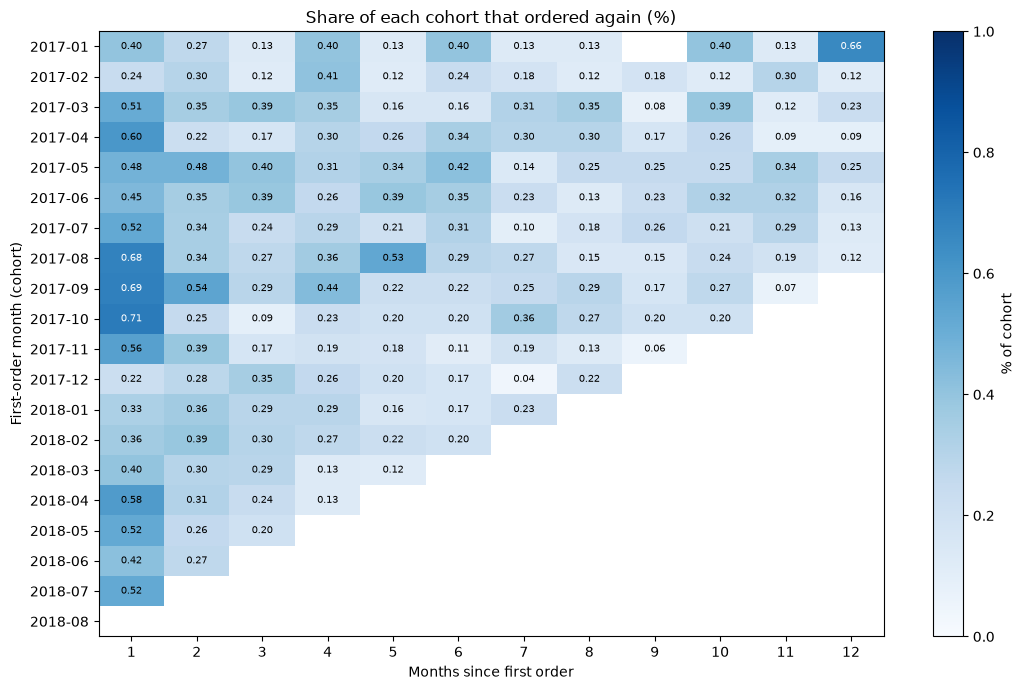

In [3]:
shown = matrix.loc[:, 1:12]
fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(shown, cmap="Blues", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(shown.shape[1]), shown.columns)
ax.set_yticks(range(shown.shape[0]), shown.index)
for i in range(shown.shape[0]):
    for j in range(shown.shape[1]):
        value = shown.iloc[i, j]
        if not np.isnan(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if value > 0.6 else "black")
ax.set_xlabel("Months since first order")
ax.set_ylabel("First-order month (cohort)")
ax.set_title("Share of each cohort that ordered again (%)")
fig.colorbar(im, ax=ax, label="% of cohort")
plt.tight_layout()
plt.savefig(IMAGES / "cohort_retention.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
pd.read_sql("""
SELECT
    month_number,
    ROUND(SUM(active_customers) * 100.0 / SUM(cohort_customers), 2) AS avg_retention_pct,
    COUNT(*) AS cohorts
FROM (""" + (SQL / "cohort_retention.sql").read_text().rstrip().rstrip(";") + """) c
WHERE month_number BETWEEN 1 AND 12
GROUP BY month_number
ORDER BY month_number
""", engine).T

,0,1,2,3,4,5,6,7,8,9,10,11
month_number,1.00,2.00,3.00,4.00,5.00,6.00,7.00,8.00,9.00,10.00,11.00,12.00
avg_retention_pct,0.48,0.34,0.26,0.26,0.22,0.23,0.21,0.21,0.17,0.26,0.21,0.18
cohorts,19.00,18.00,17.00,16.00,15.00,14.00,13.00,12.00,10.00,10.00,9.00,8.00


### Finding: cohorts
Retention never builds. In every cohort only about 0.5% of customers order again in the month after
their first purchase, and 0.2-0.3% in each later month. No cohort ever passes 0.71% in a single month.
Over the whole period, just **2.2% of customers (2,065 of 94,990) ever came back** on a later day.

### 2. Time to return
Among customers who did come back, how long did it take? `PERCENTILE_CONT` gives the quartiles directly
in SQL.

In [5]:
pd.read_sql("""
SELECT
    COUNT(*) AS returning_customers,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY days_to_return) AS p25_days,
    PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY days_to_return) AS median_days,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY days_to_return) AS p75_days,
    ROUND(AVG(CASE WHEN days_to_return <= 30 THEN 1.0 ELSE 0 END) * 100, 1) AS within_30d_pct,
    ROUND(AVG(CASE WHEN days_to_return <= 90 THEN 1.0 ELSE 0 END) * 100, 1) AS within_90d_pct,
    ROUND(AVG(CASE WHEN days_to_return <= 180 THEN 1.0 ELSE 0 END) * 100, 1) AS within_180d_pct
FROM first_orders
WHERE returned_at IS NOT NULL
""", engine).T.rename(columns={0: "value"})

,value
returning_customers,2065.0
p25_days,23.0
median_days,74.0
p75_days,175.0
within_30d_pct,29.8
within_90d_pct,54.9
within_180d_pct,75.9


### 3. What does the first order predict?
To compare groups fairly, every customer gets the same 180-day window to come back, so only first orders
placed from January 2017 to February 2018 count (the data ends in August 2018). Each table shows the
180-day return rate with a 95% confidence interval.

In [6]:
ELIGIBLE = "cohort_month BETWEEN '2017-01-01' AND '2018-02-01'"


def return_rate_by(expression, label, where="TRUE", min_customers=300):
    sql = f"""
    WITH groups AS (
        SELECT
            {expression} AS {label},
            COUNT(*) AS customers,
            AVG(CASE WHEN returned_180d THEN 1.0 ELSE 0 END) AS rate
        FROM first_orders
        WHERE {ELIGIBLE} AND {where}
        GROUP BY 1
        HAVING COUNT(*) >= {min_customers}
    )
    SELECT
        {label},
        customers,
        ROUND(rate * 100, 2) AS return_180d_pct,
        ROUND(1.96 * SQRT(rate * (1 - rate) / customers) * 100, 2) AS ci95_pct
    FROM groups
    ORDER BY return_180d_pct DESC
    """
    return pd.read_sql(sql, engine)


overall = return_rate_by("'all eligible customers'", "segment")
overall

,segment,customers,return_180d_pct,ci95_pct
0,all eligible customers,56337,1.99,0.12


In [7]:
late = return_rate_by(
    "CASE WHEN is_late THEN 'late' ELSE 'on time' END", "first_delivery", where="order_status = 'delivered'"
)
late

,first_delivery,customers,return_180d_pct,ci95_pct
0,on time,51560,2.02,0.12
1,late,3671,1.61,0.41


In [8]:
review = return_rate_by("review_score", "first_review_score", where="review_score IS NOT NULL")
review.sort_values("first_review_score")

,first_review_score,customers,return_180d_pct,ci95_pct
3,1,6175,1.68,0.32
4,2,1837,1.52,0.56
1,3,4864,1.97,0.39
2,4,11092,1.82,0.25
0,5,31910,2.15,0.16


In [9]:
category = return_rate_by("category", "first_category", min_customers=1500)
category

,first_category,customers,return_180d_pct,ci95_pct
0,bed_bath_table,5443,2.74,0.43
1,sports_leisure,4566,2.67,0.47
2,furniture_decor,3760,2.47,0.50
3,garden_tools,2332,2.14,0.59
4,perfumery,1990,2.06,0.62
5,baby,1513,2.05,0.71
6,health_beauty,4388,2.03,0.42
7,watches_gifts,2682,1.72,0.49
8,telephony,2639,1.71,0.49
9,toys,2649,1.70,0.49


In [10]:
state = return_rate_by("customer_state", "state", min_customers=1500)
state

,state,customers,return_180d_pct,ci95_pct
0,SP,22335,2.22,0.19
1,RJ,7654,2.12,0.32
2,MG,6757,1.89,0.33
3,RS,3263,1.84,0.46
4,BA,1955,1.64,0.56
5,PR,2846,1.62,0.46
6,SC,2197,1.46,0.50


In [11]:
spend = return_rate_by(
    """CASE
        WHEN payment_value < 50 THEN '1. under R$50'
        WHEN payment_value < 100 THEN '2. R$50-100'
        WHEN payment_value < 200 THEN '3. R$100-200'
        ELSE '4. R$200+'
    END""",
    "first_order_value",
    where="payment_value IS NOT NULL",
)
spend.sort_values("first_order_value")

,first_order_value,customers,return_180d_pct,ci95_pct
0,1. under R$50,9708,2.21,0.29
3,2. R$50-100,17343,1.85,0.20
2,3. R$100-200,17995,1.92,0.20
1,4. R$200+,11291,2.13,0.27


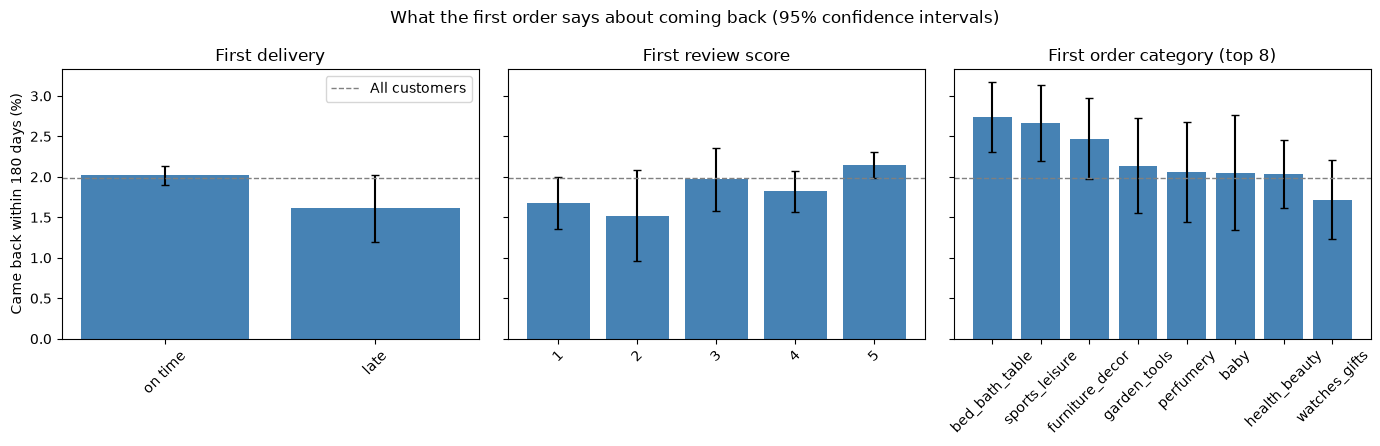

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
panels = [
    (late, "first_delivery", "First delivery"),
    (review.sort_values("first_review_score"), "first_review_score", "First review score"),
    (category.head(8), "first_category", "First order category (top 8)"),
]
for ax, (data, column, title) in zip(axes, panels):
    labels = data[column].astype(str)
    ax.bar(labels, data["return_180d_pct"], yerr=data["ci95_pct"], color="steelblue", capsize=3)
    ax.axhline(overall["return_180d_pct"].iloc[0], color="gray", linestyle="--", linewidth=1, label="All customers")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Came back within 180 days (%)")
axes[0].legend()
plt.suptitle("What the first order says about coming back (95% confidence intervals)")
plt.tight_layout()
plt.savefig(IMAGES / "return_drivers.png", dpi=150, bbox_inches="tight")
plt.show()

### Findings
- **Coming back is rare even after a great first order.** Customers whose first order arrived on time
  and got 5 stars returned within 180 days only about 2.1% of the time. The overall rate is 2.0%.
- **A late first delivery makes it worse, but not by much in absolute terms:** 1.61% vs. 2.03% for on-time
  first orders, about 20% lower. The confidence intervals barely overlap, so the effect is real but small
  next to the overall problem. 1-2 star first reviews show the same pattern (about 1.6%).
- **What was bought matters more than how it went.** Home categories bring people back most: bed/bath/table
  2.8%, sports & leisure 2.7%, furniture & decor 2.5%. One-off purchases bring them back least: "cool
  stuff" 1.0%, computer accessories 1.6%, auto 1.6%.
- Order value barely matters (1.9-2.2% across all bands). Customers in São Paulo return a little more
  often (2.2%) than in Santa Catarina (1.5%).
- When customers do return, it takes a while: median 74 days, and a quarter take more than 175 days.

**Answer:** customers mostly don't come back because Olist is where people go for one-off purchases, and
nothing pulls them back afterwards. A bad delivery lowers an already tiny return rate further, but fixing
delivery alone would not create loyalty. The levers are a reason to return (follow-up offers in
replenishable home categories, a second-order incentive timed around the 2-3 month mark) plus reliable
delivery so the first experience doesn't close the door.